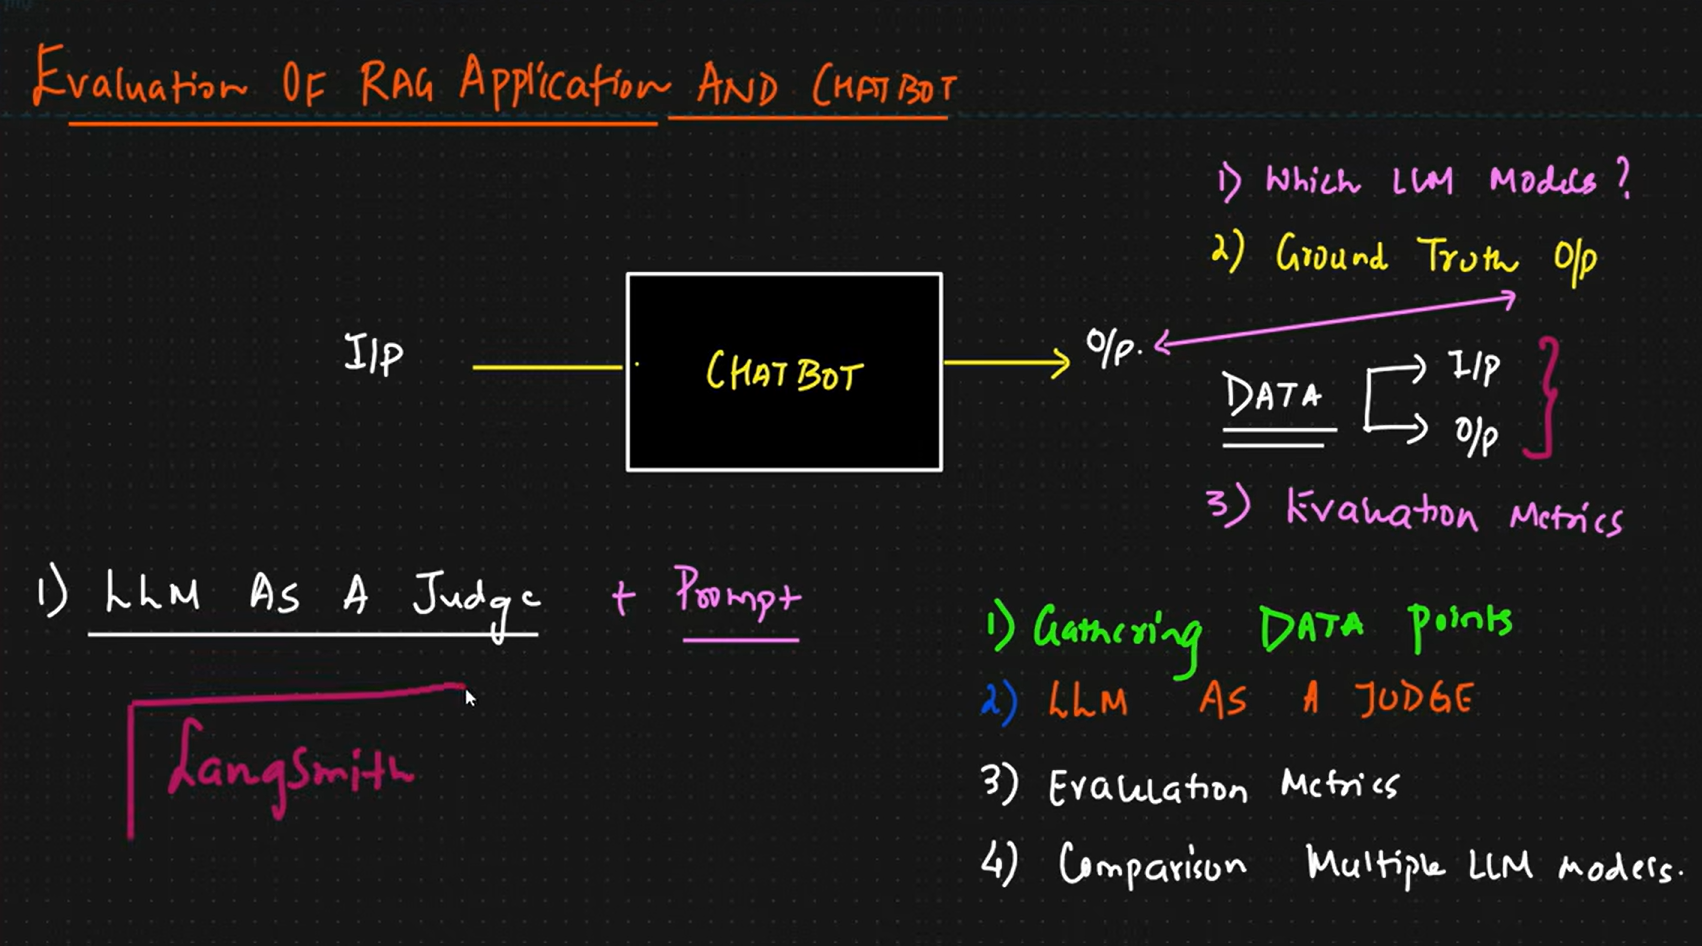


### Chatbot and RAG Evaluation

Retrieval-Augmented Generation (RAG) is a technique that enhances Large Language Models (LLMs) by providing them with relevant external knowledge. It has become one of the most widely used approaches for building LLM applications.

This tutorial will show you how to evaluate your RAG applications using **LangSmith**. You'll learn:

1. How to create test datasets
2. How to run your RAG application on those datasets
3. How to measure your application's performance using different evaluation metrics

#### Overview

A typical RAG evaluation workflow consists of three main steps:

1. Creating a dataset with questions and their expected answers
2. Running your RAG application on those questions
3. Using evaluators to measure how well your application performed, looking at factors like:
   - Answer relevance
   - Answer accuracy
   - Retrieval quality

For this tutorial, we'll create and evaluate a bot that answers questions about a few of Lilian Weng's insightful blog posts.


Chatbot Evaluation

In [1]:
import os
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv

load_dotenv(override=True)

llm = ChatOpenAI(
    model="prism-ml/ternary-bonsai-2-27b",
    api_key=os.getenv("OPENROUTER_API_KEY"),
    base_url="https://openrouter.ai/api/v1",
    max_tokens=1000,
)

os.environ["LANGSMITH_API_KEY"]=os.getenv("LANGSMITH_API_KEY")
os.environ["LANGSMITH_TRACING"]="true"

In [2]:
from langsmith import Client

client = Client()

# Define dataset: these are your test cases
dataset_name = "Chatbots Evaluation"
dataset = client.create_dataset(dataset_name)
client.create_examples(
    dataset_id=dataset.id,
    examples=[
        {
            "inputs": {"question": "What is LangChain?"},
            "outputs": {"answer": "A framework for building LLM applications"},
        },
        {
            "inputs": {"question": "What is LangSmith?"},
            "outputs": {"answer": "A platform for observing and evaluating LLM applications"},
        },
        {
            "inputs": {"question": "What is OpenAI?"},
            "outputs": {"answer": "A company that creates Large Language Models"},
        },
        {
            "inputs": {"question": "What is Google?"},
            "outputs": {"answer": "A technology company known for search"},
        },
        {
            "inputs": {"question": "What is Mistral?"},
            "outputs": {"answer": "A company that creates Large Language Models"},
        }
    ]
)

{'example_ids': ['cc83bff9-56da-49e5-85f7-36b6000c6ab6',
  '50fac0a2-1f8f-4400-bb4d-af9588efed03',
  'ec12cb66-8bb0-41c3-919d-193aa90ac6b0',
  '09a3eef3-6793-4161-a6b5-5457c5e94c82',
  '2d1a357e-6947-4ce1-b9de-5e9664e2cdaf'],
 'count': 5,
 'as_of': '2026-10-24T09:52:21.880521096Z'}